<a href="https://colab.research.google.com/github/Gayathri0616/5305_Assignments_/blob/main/dt_important_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## EX6 Supervised Learning: Classification

In [30]:
# if you need
%pip install graphviz

In [31]:
%pip install pydot

### Setup

In [32]:
# Python ≥3.5 is required
import sys
assert sys.version_info >= (3, 5)

# Scikit-Learn ≥0.20 is required
import sklearn
assert sklearn.__version__ >= "0.20"

# Common imports
import numpy as np
import pandas as pd
import os

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)


# to make this notebook's output stable across runs
np.random.seed(42)

# Where to save the figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "decision_trees"

IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)

os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Part0

- Develop a classifier using Decition Trees

    - Use two methods for criterion: Entropy and Gini

- Find important features

- Understand and implement a framework of k-cross validation

- Evaluate model performance

    - Task: Calculate the averages of k-folds

### Dataset 1: iris

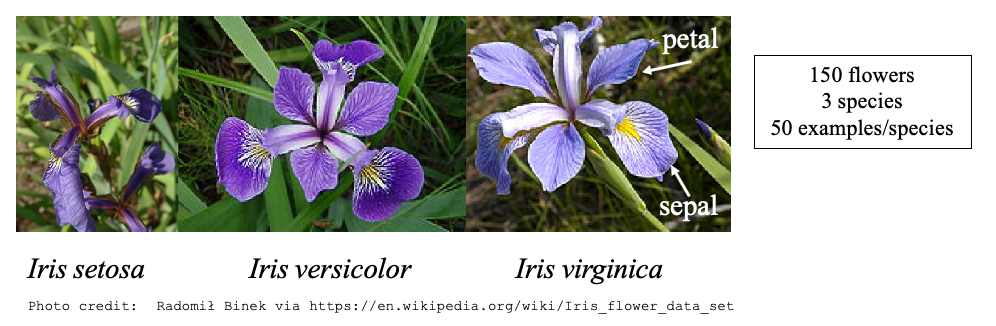

In [33]:
from sklearn.datasets import load_iris
iris = load_iris()

from IPython.display import Image

Image("images/iris.png")

#### Extract mportant features from Decition Trees

In [34]:
# a function to plot a bar graph of important features
def plot_feature_importances(clf, feature_names):
    c_features = len(feature_names)
    plt.barh(range(c_features), clf.feature_importances_)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature name")
    plt.yticks(np.arange(c_features), feature_names)


#### Important features from a decision tree

- Decision tree classifier

https://scikit-learn.org/stable/modules/tree.html#classification

- Metrics

https://scikit-learn.org/stable/modules/model_evaluation.html

#### Train-test split

- A simple way to prepare training-testing data

In [35]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# A simple training (1 training)
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, random_state = 3)

#### Build a decition tree (with 'entropy' method)

- Important features from a decision tree using information gain measure (entropy)

Accuracy of DT classifier on training set: 1.00
Accuracy of DT classifier on test set: 0.95


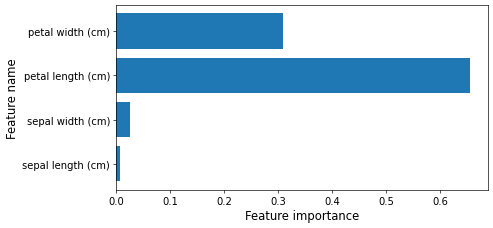

Feature importances: [0.00702077 0.02681122 0.65612204 0.31004597]


In [36]:
clf = DecisionTreeClassifier(criterion='entropy').fit(X_train, y_train)

train_score = clf.score(X_train, y_train)
test_score = clf.score(X_test, y_test)

print('Accuracy of DT classifier on training set: {:.2f}'.format(train_score))
print('Accuracy of DT classifier on test set: {:.2f}'.format(test_score))

plt.figure(figsize=(8,4), dpi=60)

# import features (call the function above)
plot_feature_importances(clf, iris.feature_names)

plt.show()

print('Feature importances: {}'.format(clf.feature_importances_))

#### DT visualization

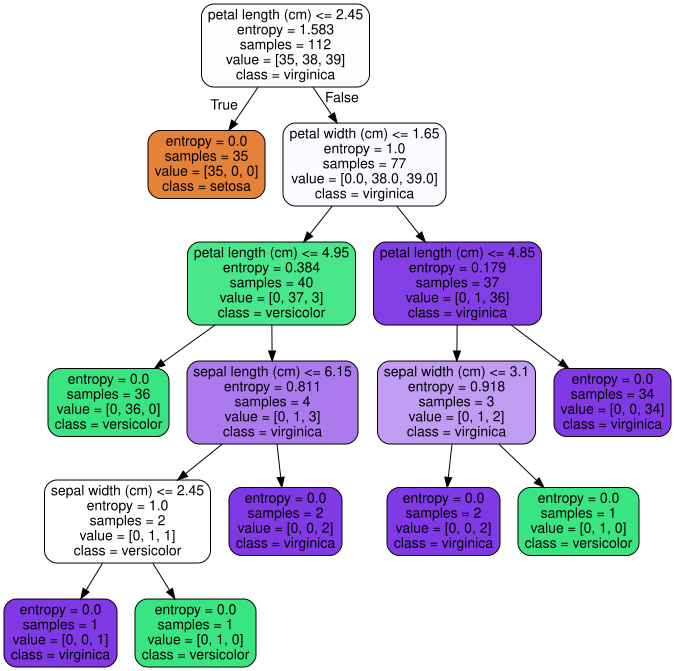

In [37]:
from graphviz import Source
from sklearn.tree import export_graphviz

export_graphviz(
        clf,
        out_file=os.path.join(IMAGES_PATH, "iris_tree1.dot"),
        feature_names=iris.feature_names[0:],
        class_names=iris.target_names,
        rounded=True,
        filled=True
    )

Source.from_file(os.path.join(IMAGES_PATH, "iris_tree1.dot"))

#### Build a decition tree (with 'gini' method)

- Important features from a decision tree using information gain measure (gini)

Accuracy of DT classifier on training set: 1.00
Accuracy of DT classifier on test set: 0.95


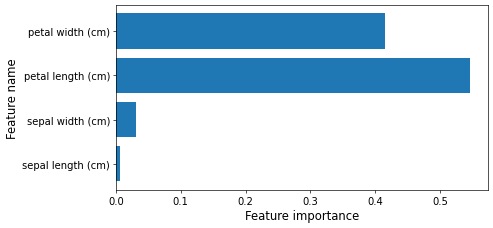

Feature importances: [0.00670338 0.03128242 0.54643762 0.41557658]


In [38]:
clf2 = DecisionTreeClassifier(criterion='gini').fit(X_train, y_train)

print('Accuracy of DT classifier on training set: {:.2f}'
     .format(clf2.score(X_train, y_train)))
print('Accuracy of DT classifier on test set: {:.2f}'
     .format(clf2.score(X_test, y_test)))

plt.figure(figsize=(8,4), dpi=60)

plot_feature_importances(clf2, iris.feature_names)

plt.show()

print('Feature importances: {}'.format(clf2.feature_importances_))

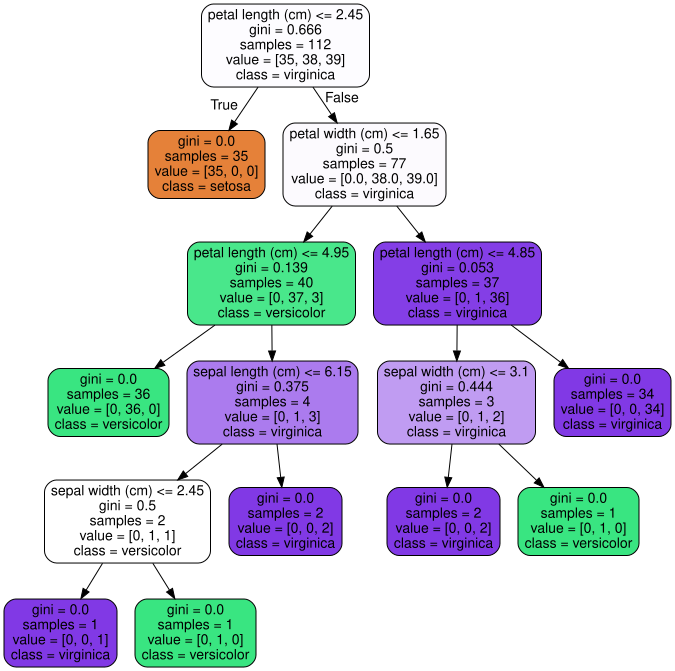

In [39]:
export_graphviz(
        clf2,
        out_file=os.path.join(IMAGES_PATH, "iris_tree2.dot"),
        feature_names=iris.feature_names[0:],
        class_names=iris.target_names,
        rounded=True,
        filled=True
    )

Source.from_file(os.path.join(IMAGES_PATH, "iris_tree2.dot"))

### k-cross validation

##### Construct a decision tree (default criterion: entropy)

In [40]:
from sklearn.model_selection import cross_val_score
from sklearn.datasets import load_iris
iris = load_iris()

X = iris.data[:, 2:] # petal length and width
y = iris.target

tree_clf = DecisionTreeClassifier(criterion='entropy', max_depth=2, random_state=40)

##### k-cross validation and averge the results

In [41]:
from sklearn.model_selection import KFold # import k-fold validation

k = 3

kf = KFold(n_splits=k, random_state=None, shuffle=True) # Define the split - into 2 folds

kf.get_n_splits(X) # returns the number of splitting iterations in the cross-validator

3

### Task: Make a summary of the model performance

<p style='color:red'>
Conduct k-cross validation and aaverage k folds' results
</p>

- For each fold, access performance measures stored in result_metrics_dict.

- Currently the code shows the content of the dictionary and an example that shows how to access 'precision' measure of a class 'setosa'.

- Calculate the averages of the following:
    - accuracy
    - precision, recall, and f1-score for each class
    - macro average of precision, recall, and f1-score
    - weighted average of precision, recall, and f1-score

In [42]:
c0_avg_precision = 0

for train_index, test_index in kf.split(X):
    #print("TRAIN:", train_index, "TEST:", test_index)
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    tree_clf.fit(X_train, y_train)
    y_pred = tree_clf.predict(X_test)

    # Print classification report
    target_names = iris.target_names
    result_metrics = classification_report(y_test, y_pred, target_names=target_names)

    print(result_metrics)

    # Once you get dictionary of metrics, access the values using dictionary
    result_metrics_dict = classification_report(y_test, y_pred, target_names=target_names, output_dict=True)

    print(result_metrics_dict)

    # this is an example to access a measure of each class
    c0_avg_precision += result_metrics_dict['setosa']['precision']

print('\n class 0: ', c0_avg_precision/k)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       0.93      1.00      0.97        14
   virginica       1.00      0.94      0.97        17

    accuracy                           0.98        50
   macro avg       0.98      0.98      0.98        50
weighted avg       0.98      0.98      0.98        50

{np.str_('setosa'): {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0, 'support': 19.0}, np.str_('versicolor'): {'precision': 0.9333333333333333, 'recall': 1.0, 'f1-score': 0.9655172413793104, 'support': 14.0}, np.str_('virginica'): {'precision': 1.0, 'recall': 0.9411764705882353, 'f1-score': 0.9696969696969697, 'support': 17.0}, 'accuracy': 0.98, 'macro avg': {'precision': 0.9777777777777779, 'recall': 0.9803921568627452, 'f1-score': 0.9784047370254267, 'support': 50.0}, 'weighted avg': {'precision': 0.9813333333333333, 'recall': 0.98, 'f1-score': 0.9800417972831766, 'support': 50.0}}
              precision   

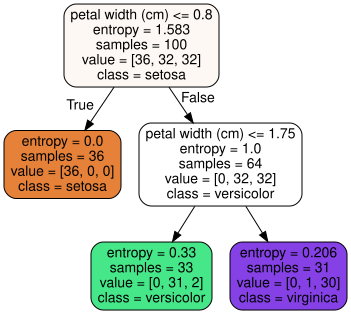

In [43]:
export_graphviz(
        tree_clf,
        out_file=os.path.join(IMAGES_PATH, "iris_tree3.dot"),
        feature_names=iris.feature_names[2:],
        class_names=iris.target_names,
        rounded=True,
        filled=True
    )

Source.from_file(os.path.join(IMAGES_PATH, "iris_tree3.dot"))

### Dataset 2: Breast Cancer dataset

In [44]:
from sklearn.datasets import load_breast_cancer

# Breast cancer dataset for classification
cancer = load_breast_cancer()
(X_cancer, y_cancer) = load_breast_cancer(return_X_y = True)

In [45]:
X_cancer.size

17070

#### Training-testing split

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X_cancer, y_cancer, random_state = 0)

In [47]:
cancer.target_names

array(['malignant', 'benign'], dtype='<U9')

#### Important features from a decision tree using entropy index¶

Accuracy of DT classifier on training set: 0.93
Accuracy of DT classifier on test set: 0.90


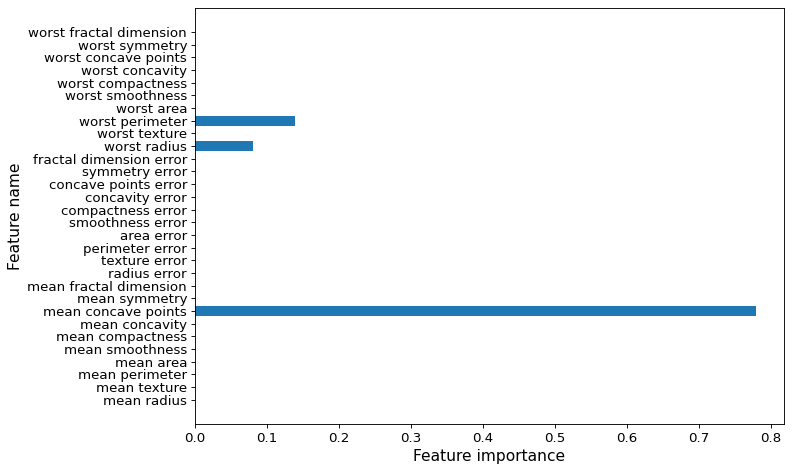

In [48]:
clf = DecisionTreeClassifier(criterion='entropy', max_depth = 2, min_samples_leaf = 8,
                            random_state = 0).fit(X_train, y_train)

print('Accuracy of DT classifier on training set: {:.2f}'
     .format(clf.score(X_train, y_train)))
print('Accuracy of DT classifier on test set: {:.2f}'
     .format(clf.score(X_test, y_test)))


plt.figure(figsize=(10,6),dpi=80)
plot_feature_importances(clf, cancer.feature_names)
plt.tight_layout()

plt.show()

#### Important features from a decision tree using gini index¶

Accuracy of DT classifier on training set: 0.96
Accuracy of DT classifier on test set: 0.94


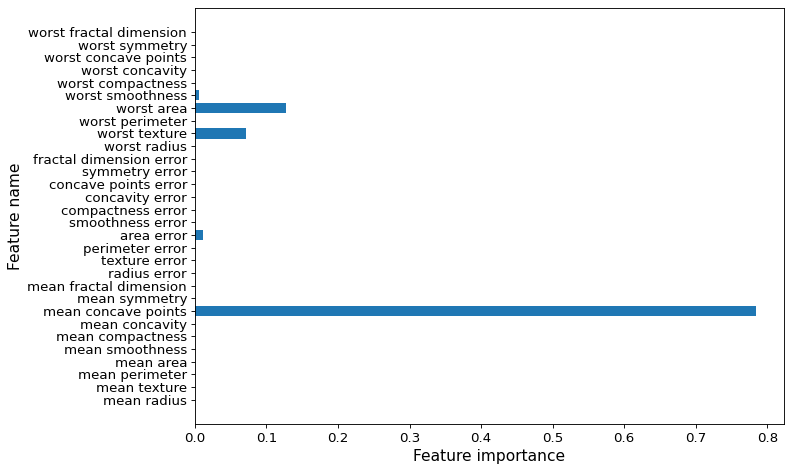

In [49]:
clf = DecisionTreeClassifier(criterion='gini', max_depth = 4, min_samples_leaf = 8,
                            random_state = 0).fit(X_train, y_train)

print('Accuracy of DT classifier on training set: {:.2f}'
     .format(clf.score(X_train, y_train)))
print('Accuracy of DT classifier on test set: {:.2f}'
     .format(clf.score(X_test, y_test)))


plt.figure(figsize=(10,6),dpi=80)
plot_feature_importances(clf, cancer.feature_names)
plt.tight_layout()

plt.show()

## Part 1

The best practice is to define a classification program for the dataset(s) of your term project.

In case a classification problem is not possibly defined for your datasets, you can use the cancer dataset in the example above.

#### 1. Construct  a decision tree using the following parameters

- Use information gain (entropy) measure
- max_depth = 2
- Apply k=3 cross validation and print a summary of statistics (performance evaluation) for each fold


#### 2. Construct  a decision tree using the following parameters

- Use information gini measure
- max_depth = 2
- Apply k=3 cross validation and print a summary of statistics (performance evaluation) for each fold

#### 3. Performance comparisons

- Compare the performance results with those of the decision tree using Gini index measure in the above example

#### 4. For both trees, change the following parameters and observe the changes:

- The depth of tree: currently max_depth=2 in the model training step. Change the depth 3, 4, 5 and check if this affects the overall results.

- The k value for cross validation is currently set to 3. Change k value, k = 5, 7, 10 and check if this affects the overall results.

In [50]:
# Part 1 setup: cancer dataset + a reusable k-fold CV helper
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report

cancer = load_breast_cancer()
X, y = cancer.data, cancer.target          # all 30 features; classes: 0 = malignant, 1 = benign

def run_cv(criterion, max_depth, k, verbose=False, seed=42):
    """k-fold CV for a decision tree. Returns a DataFrame with one row of metrics per fold.
    verbose=True prints the full classification_report of every fold."""
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)  # keeps class ratio in every fold
    rows = []
    for i, (tr, te) in enumerate(skf.split(X, y), 1):
        clf = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth,
                                     random_state=0).fit(X[tr], y[tr])
        y_pred = clf.predict(X[te])
        rep = classification_report(y[te], y_pred, target_names=cancer.target_names, output_dict=True)
        if verbose:
            print(f"--- Fold {i}  (train={len(tr)}, test={len(te)}) ---")
            print(classification_report(y[te], y_pred, target_names=cancer.target_names))
        rows.append({
            'fold': i,
            'train_acc': clf.score(X[tr], y[tr]),
            'accuracy': rep['accuracy'],
            'precision_malignant': rep['malignant']['precision'],
            'recall_malignant': rep['malignant']['recall'],
            'precision_benign': rep['benign']['precision'],
            'recall_benign': rep['benign']['recall'],
            'macro_precision': rep['macro avg']['precision'],
            'macro_recall': rep['macro avg']['recall'],
            'macro_f1': rep['macro avg']['f1-score'],
            'weighted_f1': rep['weighted avg']['f1-score'],
        })
    return pd.DataFrame(rows).set_index('fold')

def summarize(df):
    pd.set_option('display.width', 200)
    print("Per-fold metrics:")
    print(df.round(4))
    print("\nAverage over folds (mean +/- std):")
    print(pd.DataFrame({'mean': df.mean(), 'std': df.std()}).round(4))

In [51]:
 #Decision tree: entropy (information gain), max_depth = 2, k = 3
 df_entropy = run_cv('entropy', max_depth=2, k=3, verbose=True)
summarize(df_entropy)

--- Fold 1  (train=379, test=190) ---
              precision    recall  f1-score   support

   malignant       0.88      0.89      0.88        71
      benign       0.93      0.92      0.93       119

    accuracy                           0.91       190
   macro avg       0.90      0.91      0.90       190
weighted avg       0.91      0.91      0.91       190

--- Fold 2  (train=379, test=190) ---
              precision    recall  f1-score   support

   malignant       0.74      0.89      0.81        71
      benign       0.92      0.82      0.87       119

    accuracy                           0.84       190
   macro avg       0.83      0.85      0.84       190
weighted avg       0.86      0.84      0.84       190

--- Fold 3  (train=380, test=189) ---
              precision    recall  f1-score   support

   malignant       0.87      0.96      0.91        70
      benign       0.97      0.92      0.94       119

    accuracy                           0.93       189
   macro avg  

In [52]:
#2. Decision tree: gini, max_depth = 2, k = 3
df_gini = run_cv('gini', max_depth=2, k=3, verbose=True)
summarize(df_gini)

--- Fold 1  (train=379, test=190) ---
              precision    recall  f1-score   support

   malignant       0.88      0.86      0.87        71
      benign       0.92      0.93      0.93       119

    accuracy                           0.91       190
   macro avg       0.90      0.90      0.90       190
weighted avg       0.90      0.91      0.90       190

--- Fold 2  (train=379, test=190) ---
              precision    recall  f1-score   support

   malignant       0.90      0.85      0.87        71
      benign       0.91      0.94      0.93       119

    accuracy                           0.91       190
   macro avg       0.90      0.89      0.90       190
weighted avg       0.90      0.91      0.90       190

--- Fold 3  (train=380, test=189) ---
              precision    recall  f1-score   support

   malignant       0.92      0.96      0.94        70
      benign       0.97      0.95      0.96       119

    accuracy                           0.95       189
   macro avg  

3. Performance comparison
Compares the two CV models above with the earlier cancer example (gini, max_depth=4, min_samples_leaf=8, a single 75/25 train-test split).

In [53]:
from sklearn.model_selection import train_test_split

# Earlier example: gini, max_depth=4, min_samples_leaf=8, one train/test split
X_tr, X_te, y_tr, y_te = train_test_split(X, y, random_state=0)
base = DecisionTreeClassifier(criterion='gini', max_depth=4, min_samples_leaf=8,
                              random_state=0).fit(X_tr, y_tr)
rep = classification_report(y_te, base.predict(X_te), target_names=cancer.target_names, output_dict=True)

compare = pd.DataFrame({
    'entropy, depth=2, 3-fold CV': df_entropy.mean(),
    'gini, depth=2, 3-fold CV':    df_gini.mean(),
}).loc[['train_acc', 'accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'weighted_f1']]
compare['earlier example (gini, depth=4, single split)'] = [
    base.score(X_tr, y_tr), rep['accuracy'], rep['macro avg']['precision'],
    rep['macro avg']['recall'], rep['macro avg']['f1-score'], rep['weighted avg']['f1-score']]
print(compare.round(4))

# Is the entropy-vs-gini gap real or just fold-to-fold noise? Repeat the 3-fold CV with 5 different shuffles.
for crit in ['entropy', 'gini']:
    accs = [run_cv(crit, 2, 3, seed=s)['accuracy'].mean() for s in range(5)]
    print(f"{crit:8s} depth=2, k=3, 5 shuffles: mean acc = {np.mean(accs):.4f}  (range {min(accs):.4f}-{max(accs):.4f})")

                 entropy, depth=2, 3-fold CV  gini, depth=2, 3-fold CV  earlier example (gini, depth=4, single split)
train_acc                             0.9332                    0.9569                                         0.9648
accuracy                              0.8946                    0.9210                                         0.9371
macro_precision                       0.8859                    0.9166                                         0.9273
macro_recall                          0.8979                    0.9141                                         0.9461
macro_f1                              0.8897                    0.9151                                         0.9342
weighted_f1                           0.8956                    0.9207                                         0.9377
entropy  depth=2, k=3, 5 shuffles: mean acc = 0.9069  (range 0.8981-0.9174)
gini     depth=2, k=3, 5 shuffles: mean acc = 0.9227  (range 0.9069-0.9350)


4. Effect of tree depth and of k
Mean CV accuracy for every combination of depth (2, 3, 4, 5) and k (3, 5, 7, 10).

Mean CV accuracy - entropy
k              3       5       7       10
max_depth                                
2          0.8946  0.8859  0.9085  0.9017
3          0.9350  0.9121  0.9190  0.9139
4          0.9367  0.9297  0.9332  0.9263
5          0.9367  0.9385  0.9349  0.9245 

Mean CV accuracy - gini
k              3       5       7       10
max_depth                                
2          0.9210  0.9052  0.9157  0.9087
3          0.9315  0.9174  0.9225  0.9174
4          0.9385  0.9280  0.9173  0.9245
5          0.9350  0.9280  0.9261  0.9210 



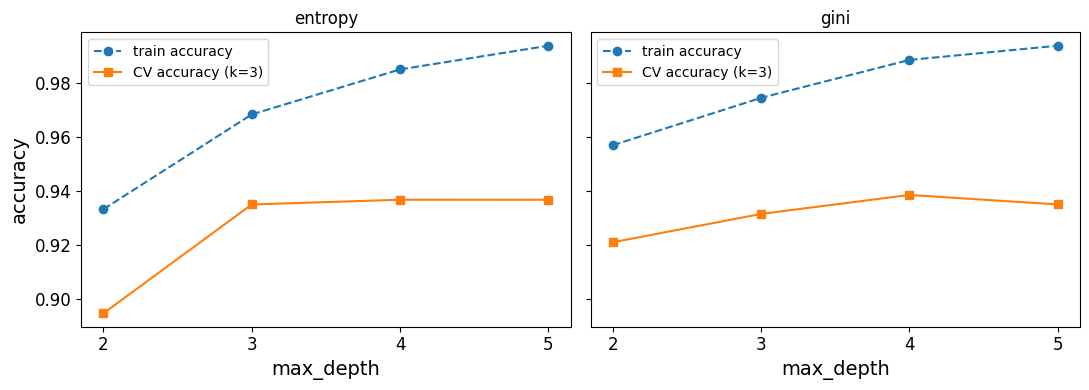

In [54]:
depths, ks = [2, 3, 4, 5], [3, 5, 7, 10]
grid = {}
for crit in ['entropy', 'gini']:
    g = pd.DataFrame(index=pd.Index(depths, name='max_depth'), columns=pd.Index(ks, name='k'), dtype=float)
    for d in depths:
        for k in ks:
            g.loc[d, k] = run_cv(crit, d, k)['accuracy'].mean()
    grid[crit] = g
    print(f"Mean CV accuracy - {crit}")
    print(g.round(4), "\n")

# Depth effect at k=3: train vs CV accuracy shows over-fitting as depth grows
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, crit in zip(axes, ['entropy', 'gini']):
    tr = [run_cv(crit, d, 3)['train_acc'].mean() for d in depths]
    ax.plot(depths, tr, 'o--', label='train accuracy')
    ax.plot(depths, grid[crit][3], 's-', label='CV accuracy (k=3)')
    ax.set_title(crit); ax.set_xlabel('max_depth'); ax.set_xticks(depths); ax.legend()
axes[0].set_ylabel('accuracy')
plt.tight_layout(); plt.show()

In [55]:
# k effect at max_depth=2: mean and std of per-fold accuracy
rows = []
for crit in ['entropy', 'gini']:
    for k in ks:
        a = run_cv(crit, 2, k)['accuracy']
        rows.append({'criterion': crit, 'k': k, 'mean_acc': a.mean(), 'std_across_folds': a.std()})
print(pd.DataFrame(rows).round(4).to_string(index=False))

criterion  k  mean_acc  std_across_folds
  entropy  3    0.8946            0.0466
  entropy  5    0.8859            0.0295
  entropy  7    0.9085            0.0434
  entropy 10    0.9017            0.0454
     gini  3    0.9210            0.0272
     gini  5    0.9052            0.0357
     gini  7    0.9157            0.0356
     gini 10    0.9087            0.0473


### Part2

Write a summary

Setup. Breast-cancer dataset (569 samples, 30 features, malignant vs. benign). All CV runs use stratified k-fold with shuffling (seed 42), so each fold keeps the class ratio. Trees use random_state=0.

1-2. Entropy vs. gini at depth 2, k = 3. Mean CV accuracy was 0.895 for entropy and 0.921 for gini, and macro-F1 followed the same pattern (0.890 vs. 0.915). Fold-to-fold spread is large (entropy std about 0.047, gini about 0.027). Entropy's weakest fold (fold 2, accuracy 0.842) dragged its average down, with malignant precision of only 0.74. Repeating the 3-fold CV over 5 shuffles gave 0.907 for entropy and 0.923 for gini, so gini is slightly ahead at depth 2, but the gap (about 1.5 points) is small relative to the fold noise. At such a shallow depth the two criteria can pick different root and second splits, which explains the difference. I would not claim one criterion is better in general.

3. Comparison with the earlier example (gini, depth 4, min_samples_leaf=8, one split): test accuracy 0.937, macro-F1 0.934. That is higher than both depth-2 CV models (0.895 and 0.921), mainly because depth 4 can model the data better than depth 2. It is also a single split, which is a noisier estimate than a 3-fold average. The depth-4 gini CV result (0.939 at k = 3) agrees with it.

4a. Depth (k = 3). Going from depth 2 to 3 helps both trees (entropy 0.895 to 0.935, gini 0.921 to 0.932), and depth 4 gives a small further gain (0.937 / 0.939). Depth 5 does not improve on depth 4 (0.937 / 0.935), while training accuracy keeps rising toward 0.994, so the train-CV gap widens. That is the start of over-fitting. Depth 3 to 4 looks like the sweet spot. As depth grows, entropy catches up with gini and the difference between the two criteria almost disappears.

4b. k. Changing k has a much smaller and less systematic effect than changing depth. At depth 2, mean accuracy moves within roughly 0.886-0.909 for entropy and 0.905-0.921 for gini, with no consistent trend. k = 3 looks best for gini at most depths, but that is mostly noise, because each configuration is a single shuffled run and the std across folds is about 0.03-0.05. Larger k trains on more data per fold (and gives a slightly less pessimistic estimate) but costs more compute. In general a larger k yields a lower-bias estimate with more fits, and k = 5 or 10 is the usual choice.